# P-1 Random Forest Lag Selection with Time-Series Cross-Validation

This notebook selects the Random Forest lag length using **only the official P-1 training data**.

For each candidate lag \(p\), the model uses the previous \(p\) rows of:

- telemetry,
- all 24 context/command variables,

to predict the current telemetry value.

The lag and Random Forest configuration are selected by the **lowest mean validation MAE across 5 time-series CV folds**.

The P-1 test set and anomaly labels are not used here.


In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error


def find_repo_root():
    cwd = Path.cwd().resolve()

    for candidate in [cwd] + list(cwd.parents[:4]):
        p1_file = candidate / "data" / "data" / "train" / "P-1.npy"

        if p1_file.is_file():
            return candidate

    raise FileNotFoundError(
        "Could not find data/data/train/P-1.npy. "
        "Run this notebook from the project repository or one of its subfolders."
    )


repo_dir = find_repo_root()
data_dir = repo_dir / "data" / "data"

print("Repository root:", repo_dir)
print("Data directory:", data_dir)


Repository root: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors
Data directory: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors/data/data


## 1. Load the official P-1 training data

In [2]:
p1_train = np.load(
    data_dir / "train" / "P-1.npy"
)

train_signal = p1_train[:, 0]
train_context = p1_train[:, 1:]

context_names = [
    f"context_{j}"
    for j in range(1, train_context.shape[1] + 1)
]

print("Training shape:", p1_train.shape)
print("Telemetry columns:", 1)
print("Context columns:", train_context.shape[1])


Training shape: (2872, 25)
Telemetry columns: 1
Context columns: 24


## 2. Choose lag candidates

Edit this list if you want to compare a different set.

The default candidates are:

```python
[1, 2, 3, 5, 10, 20]
```


In [3]:
LAG_CANDIDATES = [1, 2, 3, 5, 10, 20]

MAX_LAG = max(LAG_CANDIDATES)

print("Lag candidates:", LAG_CANDIDATES)
print("Maximum lag:", MAX_LAG)


Lag candidates: [1, 2, 3, 5, 10, 20]
Maximum lag: 20


## 3. Build lagged predictors

To make the comparison fair, **every lag candidate is evaluated on the exact same target observations**.

Because the largest candidate is `MAX_LAG`, every model is evaluated starting at target index `MAX_LAG`.

Thus lag 1 and lag 20 have:

- the same response vector,
- the same validation periods,
- the same five time-series CV folds.


In [4]:
def make_lagged_matrix(data, target_indices, n_lags):
    """Build lagged telemetry + context predictors."""
    target_indices = np.asarray(target_indices)

    if np.min(target_indices) < n_lags:
        raise ValueError("Target indices must be at least n_lags.")

    blocks = []
    names = []

    for lag in range(1, n_lags + 1):
        blocks.append(
            data[target_indices - lag, :]
        )

        names.append(
            f"telemetry_lag{lag}"
        )

        names.extend([
            f"{name}_lag{lag}"
            for name in context_names
        ])

    return np.hstack(blocks), names


common_target_indices = np.arange(
    MAX_LAG,
    len(p1_train)
)

y_common = p1_train[
    common_target_indices,
    0
]

X_by_lag = {}
names_by_lag = {}

for lag in LAG_CANDIDATES:
    X_lag, names_lag = make_lagged_matrix(
        p1_train,
        common_target_indices,
        lag
    )

    X_by_lag[lag] = X_lag
    names_by_lag[lag] = names_lag

    print(
        f"Lag {lag:>2}: "
        f"{X_lag.shape[0]} rows, "
        f"{X_lag.shape[1]} predictors"
    )

print("Common response rows:", len(y_common))


Lag  1: 2852 rows, 25 predictors
Lag  2: 2852 rows, 50 predictors
Lag  3: 2852 rows, 75 predictors
Lag  5: 2852 rows, 125 predictors
Lag 10: 2852 rows, 250 predictors
Lag 20: 2852 rows, 500 predictors
Common response rows: 2852


## 4. Random Forest configurations

These are the same six structural configurations used in the earlier P-1 Random Forest analysis.

The number of trees is fixed at 200 during cross-validation.


In [5]:
rf_candidates = [
    {
        "max_depth": 5,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    {
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    {
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": 1.0
    },
    {
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": 1.0
    }
]

N_TREES_CV = 200
N_SPLITS = 5

print("RF configurations:", len(rf_candidates))
print("Trees per CV model:", N_TREES_CV)
print("CV folds:", N_SPLITS)


RF configurations: 6
Trees per CV model: 200
CV folds: 5


## 5. Create the common time-series CV folds

The folds are created once and reused for every lag and RF configuration.


In [6]:
tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

cv_splits = list(
    tscv.split(y_common)
)

fold_rows = []

for fold, (fit_idx, val_idx) in enumerate(
    cv_splits,
    start=1
):
    fold_rows.append({
        "fold": fold,
        "training_rows": len(fit_idx),
        "validation_rows": len(val_idx),
        "first_validation_target": int(
            common_target_indices[val_idx[0]]
        ),
        "last_validation_target": int(
            common_target_indices[val_idx[-1]]
        )
    })

fold_summary = pd.DataFrame(fold_rows)

display(fold_summary)


,fold,training_rows,validation_rows,first_validation_target,last_validation_target
0,1,477,475,497,971
1,2,952,475,972,1446
2,3,1427,475,1447,1921
3,4,1902,475,1922,2396
4,5,2377,475,2397,2871


## 6. Run cross-validation

For every lag/configuration combination, calculate validation MAE in all five folds.


In [7]:
cv_rows = []

start_time = time.perf_counter()

total = (
    len(LAG_CANDIDATES)
    * len(rf_candidates)
)

combo = 0

for lag in LAG_CANDIDATES:
    X_lag = X_by_lag[lag]

    for candidate_id, params in enumerate(
        rf_candidates,
        start=1
    ):
        combo += 1

        print(
            f"Combination {combo}/{total}: "
            f"lag={lag}, candidate={candidate_id}"
        )

        for fold, (fit_idx, val_idx) in enumerate(
            cv_splits,
            start=1
        ):
            model = RandomForestRegressor(
                n_estimators=N_TREES_CV,
                random_state=42,
                n_jobs=-1,
                **params
            )

            model.fit(
                X_lag[fit_idx],
                y_common[fit_idx]
            )

            predictions = model.predict(
                X_lag[val_idx]
            )

            mae = mean_absolute_error(
                y_common[val_idx],
                predictions
            )

            cv_rows.append({
                "lag": lag,
                "candidate": candidate_id,
                "fold": fold,
                "max_depth": params["max_depth"],
                "min_samples_leaf": params["min_samples_leaf"],
                "max_features": params["max_features"],
                "n_predictors": X_lag.shape[1],
                "validation_MAE": mae
            })

elapsed = time.perf_counter() - start_time

cv_results = pd.DataFrame(cv_rows)

print()
print("Total CV computation time (seconds):", elapsed)

display(cv_results.head(15))


Combination 1/36: lag=1, candidate=1
Combination 2/36: lag=1, candidate=2
Combination 3/36: lag=1, candidate=3
Combination 4/36: lag=1, candidate=4
Combination 5/36: lag=1, candidate=5
Combination 6/36: lag=1, candidate=6
Combination 7/36: lag=2, candidate=1
Combination 8/36: lag=2, candidate=2
Combination 9/36: lag=2, candidate=3
Combination 10/36: lag=2, candidate=4
Combination 11/36: lag=2, candidate=5
Combination 12/36: lag=2, candidate=6
Combination 13/36: lag=3, candidate=1
Combination 14/36: lag=3, candidate=2
Combination 15/36: lag=3, candidate=3
Combination 16/36: lag=3, candidate=4
Combination 17/36: lag=3, candidate=5
Combination 18/36: lag=3, candidate=6
Combination 19/36: lag=5, candidate=1
Combination 20/36: lag=5, candidate=2
Combination 21/36: lag=5, candidate=3
Combination 22/36: lag=5, candidate=4
Combination 23/36: lag=5, candidate=5
Combination 24/36: lag=5, candidate=6
Combination 25/36: lag=10, candidate=1
Combination 26/36: lag=10, candidate=2
Combination 27/36: 

,lag,candidate,fold,max_depth,min_samples_leaf,max_features,n_predictors,validation_MAE
0,1,1,1,5.0,1,sqrt,25,0.163155
1,1,1,2,5.0,1,sqrt,25,0.161480
2,1,1,3,5.0,1,sqrt,25,0.160573
3,1,1,4,5.0,1,sqrt,25,0.164622
4,1,1,5,5.0,1,sqrt,25,0.191217
5,1,2,1,10.0,1,sqrt,25,0.131749
6,1,2,2,10.0,1,sqrt,25,0.122985
7,1,2,3,10.0,1,sqrt,25,0.127141
8,1,2,4,10.0,1,sqrt,25,0.120195
9,1,2,5,10.0,1,sqrt,25,0.130079


## 7. Summarize every lag/configuration combination

Lower mean validation MAE is better.


In [8]:
cv_summary = (
    cv_results
    .groupby(
        [
            "lag",
            "candidate",
            "max_depth",
            "min_samples_leaf",
            "max_features",
            "n_predictors"
        ],
        dropna=False,
        as_index=False
    )
    .agg(
        mean_validation_MAE=(
            "validation_MAE",
            "mean"
        ),
        sd_validation_MAE=(
            "validation_MAE",
            "std"
        )
    )
    .sort_values(
        "mean_validation_MAE"
    )
    .reset_index(drop=True)
)

display(cv_summary)


,lag,candidate,max_depth,min_samples_leaf,max_features,n_predictors,mean_validation_MAE,sd_validation_MAE
0,10,6,NaN,5,1.0,250,0.107912,0.008067
1,10,5,10.0,5,1.0,250,0.107935,0.008056
2,20,6,NaN,5,1.0,500,0.110307,0.011508
3,20,5,10.0,5,1.0,500,0.110630,0.011402
4,5,5,10.0,5,1.0,125,0.110707,0.006717
5,5,6,NaN,5,1.0,125,0.111014,0.006579
6,3,5,10.0,5,1.0,75,0.115683,0.005122
7,3,6,NaN,5,1.0,75,0.116198,0.004795
8,2,5,10.0,5,1.0,50,0.121271,0.003586
9,2,6,NaN,5,1.0,50,0.122130,0.003195


## 8. Best RF configuration for each lag

This produces one best training-CV result per lag.


In [13]:
best_by_lag = (
    cv_summary
    .sort_values(
        ["lag", "mean_validation_MAE"]
    )
    .groupby("lag", group_keys=False)
    .head(1)
    .sort_values("lag")
    .reset_index(drop=True)
)

display(best_by_lag)


,lag,candidate,max_depth,min_samples_leaf,max_features,n_predictors,mean_validation_MAE,sd_validation_MAE
0,1,2,10.0,1,sqrt,25,0.126430,0.004818
1,2,5,10.0,5,1.0,50,0.121271,0.003586
2,3,5,10.0,5,1.0,75,0.115683,0.005122
3,5,5,10.0,5,1.0,125,0.110707,0.006717
4,10,6,NaN,5,1.0,250,0.107912,0.008067
5,20,6,NaN,5,1.0,500,0.110307,0.011508


## 9. Plot CV MAE by lag

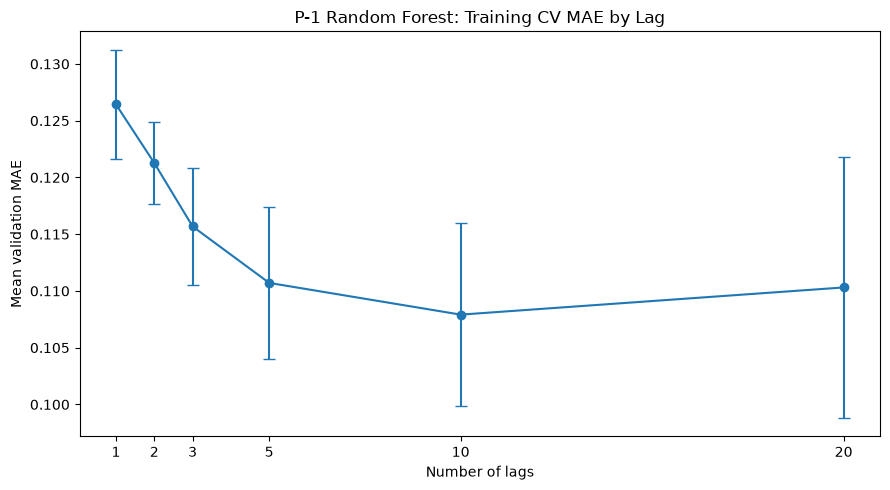

In [14]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.errorbar(
    best_by_lag["lag"],
    best_by_lag["mean_validation_MAE"],
    yerr=best_by_lag["sd_validation_MAE"],
    marker="o",
    capsize=4
)

ax.set(
    title="P-1 Random Forest: Training CV MAE by Lag",
    xlabel="Number of lags",
    ylabel="Mean validation MAE"
)

ax.set_xticks(
    best_by_lag["lag"]
)

plt.tight_layout()
plt.show()


## 10. Select the final lag and RF configuration

The selected combination is the one with the lowest mean validation MAE across the five training folds.


In [15]:
best_row = cv_summary.iloc[0]

SELECTED_LAG = int(
    best_row["lag"]
)

SELECTED_CANDIDATE = int(
    best_row["candidate"]
)

SELECTED_PARAMS = rf_candidates[
    SELECTED_CANDIDATE - 1
]

print("Selected lag:", SELECTED_LAG)
print("Selected RF candidate:", SELECTED_CANDIDATE)
print("Selected parameters:", SELECTED_PARAMS)
print("Number of predictors:", int(best_row["n_predictors"]))
print("Mean validation MAE:", best_row["mean_validation_MAE"])
print("SD validation MAE:", best_row["sd_validation_MAE"])


Selected lag: 10
Selected RF candidate: 6
Selected parameters: {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 1.0}
Number of predictors: 250
Mean validation MAE: 0.10791227933065892
SD validation MAE: 0.008066794286026701


## 11. Fold-by-fold MAE for the selected combination


In [16]:
selected_fold_results = (
    cv_results.loc[
        (cv_results["lag"] == SELECTED_LAG)
        & (
            cv_results["candidate"]
            == SELECTED_CANDIDATE
        )
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    selected_fold_results[
        [
            "fold",
            "validation_MAE"
        ]
    ]
)


,fold,validation_MAE
0,1,0.121583
1,2,0.101124
2,3,0.108030
3,4,0.103229
4,5,0.105595


# Interpretation

The lag selected here is the statistically cleaner choice for the final Random Forest because it was selected using **training-data forecasting performance only**.

If lag 3 is selected, then the RF(3) anomaly-detection result has independent support from the training CV analysis.

If another lag is selected, then the earlier lag-3 result should be treated as an exploratory sensitivity result rather than the basis for model selection.

This notebook intentionally does **not** load the P-1 test set, anomaly labels, or `detection.py`.
